# Online Tracking and Privacy
**NWI-IMC074 · Assignment 2**

This notebook includes the report text and the captured tables and figures. The saved results are visible without running any cells. To refresh them from the PyCharm project, open this notebook with the project's Python environment, check `PROJECT`, and run all cells. Set `RECOMPUTE = True` to rerun Q1–Q12 with the prepared CSVs and saved DNS cache.


In [5]:
from pathlib import Path
import csv
import html
import os
import shutil
import sys
import tempfile
from IPython.display import HTML, Image, display

PROJECT = Path.home() / "PycharmProjects" / "Web-Privacy-Measurement"
RECOMPUTE = True
OUTPUT = PROJECT / "analysis" / "output"
if not OUTPUT.is_dir():
    raise FileNotFoundError(f"Set PROJECT to the project containing analysis/output: {PROJECT}")

if RECOMPUTE:
    os.environ["MPLBACKEND"] = "Agg"
    sys.path.insert(0, str(PROJECT))
    from analysis import questions
    from unittest.mock import patch

    # Keep the temporary directory alive so later cells can read the results.
    refreshed_run = tempfile.TemporaryDirectory(prefix="tracking-assignment-")
    run_root = Path(refreshed_run.name)
    analysis_copy = run_root / "analysis"
    OUTPUT = analysis_copy / "output"
    OUTPUT.mkdir(parents=True)
    for name in ("requests.csv", "visits.csv", "dns_cache.json"):
        shutil.copy2(PROJECT / "analysis" / "output" / name, OUTPUT / name)
    for name in ("tranco.csv", "services.json", "entities.json"):
        shutil.copy2(PROJECT / "analysis" / name, analysis_copy / name)

    def require_cached_dns(hostname):
        raise RuntimeError(f"Missing saved DNS record for {hostname}. Use the original DNS cache for reproducible results.")

    with patch.object(questions, "cname_chain", side_effect=require_cached_dns):
        for number in range(1, 13):
            questions.QUESTIONS[number](run_root)


In [6]:
def table_html(rows, label, caption):
    def row_html(row, tag):
        return "<tr>" + "".join(f"<{tag}>{html.escape(str(cell))}</{tag}>" for cell in row) + "</tr>"

    header, *data = rows
    title = f"<b>Table {html.escape(label)}.</b> {html.escape(caption)}"
    return (
        f'<table style="width:100%;text-align:left">'
        f'<caption style="caption-side:top;text-align:left">{title}</caption>'
        f"<thead>{row_html(header, 'th')}</thead><tbody>"
        + "".join(row_html(row, "td") for row in data)
        + "</tbody></table>"
    )


def table_rows(key, kind, detail, output_dir):
    with (output_dir / f"{key}.csv").open(newline="", encoding="utf-8") as file:
        rows = list(csv.reader(file))
    if kind == "summary":
        headers = [detail, "Sites", "All requests", "Third-party requests",
                   "Third-party domains", "Mapped third-party entities"]
        return [headers] + [
            row[:2] + [
                " / ".join(value.removesuffix(".0") for value in row[i:i + 3])
                for i in range(2, 14, 3)
            ]
            for row in rows[1:]
        ]
    if kind == "rank":
        return [["Website", "Tranco rank", "Country", "Third-party domains"]] + [
            row[:2] + [row[2].upper(), row[3]] for row in rows[1:]
        ]
    if detail:
        rows[0] = detail
    return rows


def show_table(key, label, caption, kind="table", detail=None):
    display(HTML(table_html(table_rows(key, kind, detail, OUTPUT), label, caption)))


def show_figure(key, label, caption):
    display(Image(filename=str(OUTPUT / f"{key}.png"), width=660, alt=caption))
    display(HTML(f"<p><b>Figure {html.escape(label)}.</b> {html.escape(caption)}</p>"))


A comparative measurement of 30 university homepages across four browser configurations.


### Measurement design

The sample comprised ten universities each from the Netherlands (NL), United Kingdom (UK) and United States (US). Crawl attempts took place on 16 November 2026, between 16:47 and 18:05 UTC, using Playwright 1.64.1 and headless Chromium 156.0.8078.4. The crawler used fresh contexts, an en-GB locale, the Europe/Amsterdam browser time zone and blocked service workers.

Desktop used a 1366 × 768 viewport. Mobile emulated a Pixel 10. Both attempted to accept all cookies when a consent dialog was detected. Block used the desktop configuration and the same consent procedure, with Disconnect-based blocking for Advertising, Analytics, Social, FingerprintingInvasive and FingerprintingGeneral. Ignore used the desktop configuration and left consent untouched.

The crawler waited 10 seconds after page load, handled consent where applicable, waited 5 seconds, scrolled, then waited 5 seconds before closing. Ignore skipped the consent interaction and its associated wait.

<table class=""><caption><b>Table 1.</b> Coverage, logged consent outcomes and received HTTP responses by mode.</caption><tr><th>Mode</th><th>Completed</th><th>Consent outcome</th><th>Responses</th></tr><tr><td>Desktop</td><td>30 / 30</td><td>21 accepted, 9 not found</td><td>3,195</td></tr><tr><td>Mobile</td><td>29 / 30</td><td>21 accepted, 8 not found</td><td>3,120</td></tr><tr><td>Block</td><td>30 / 30</td><td>21 accepted, 9 not found</td><td>2,256</td></tr><tr><td>Ignore</td><td>30 / 30</td><td>30 untouched</td><td>2,039</td></tr></table>

The Mobile visit to nottingham.ac.uk failed during consent interaction and was excluded. Mobile therefore includes nine UK sites. “Not found” is the crawler’s recorded outcome for consent detection.


### Analysis rules

The analysis covers 10,610 HTTP(S) requests with a recorded response status of 100–599, including redirects and HTTP errors. Each response’s registrable domain (eTLD+1) was compared with the final page’s registrable domain using the local Public Suffix List, including its private section. Of 5,246 third-party responses, 3,485 (66.4%) had at least one mapped entity. Unmapped entities contributed zero to the distinct-entity count.


## Request distributions


### Q1. Traffic per completed visit

Each plot uses Desktop (30 visits), Mobile (29), Block (30) and Ignore (30). Boxes span the first and third quartiles, with the median marked inside. Whiskers end at the furthest observations within 1.5 interquartile ranges of the box. Circles mark observations beyond the whiskers. Completed visits with zero counts are included.


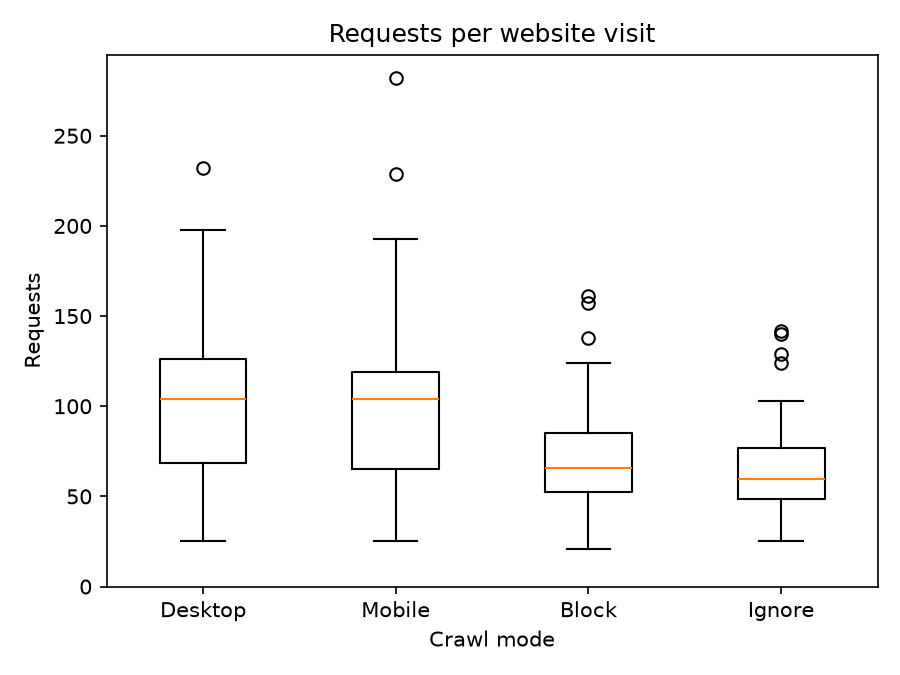

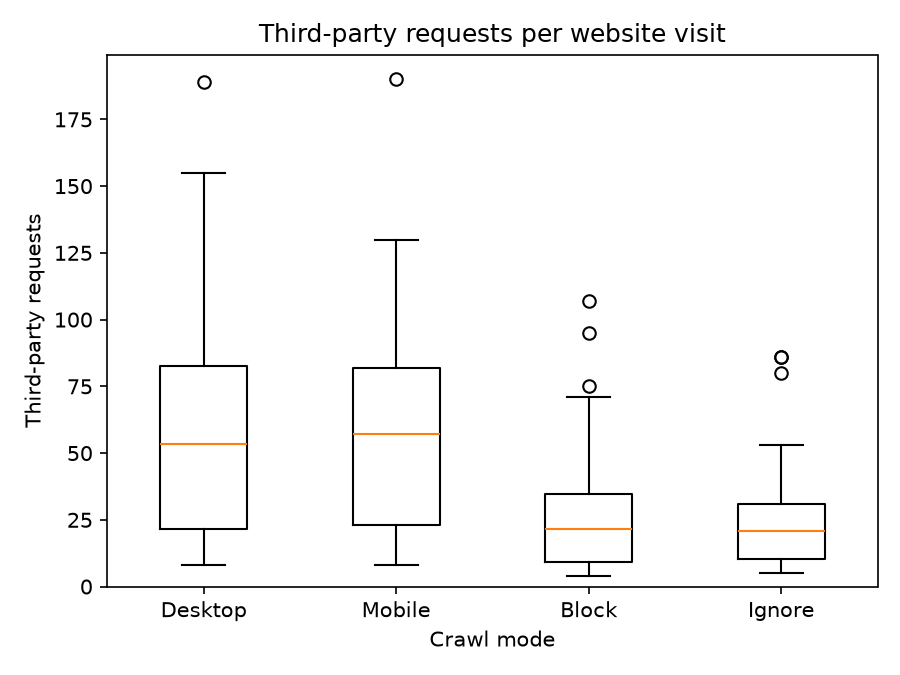

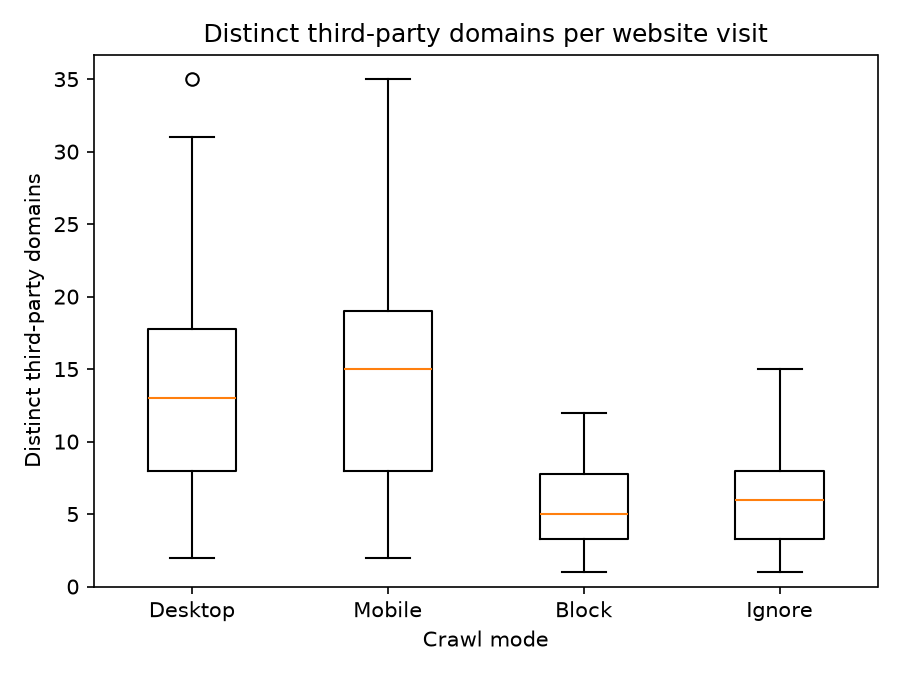

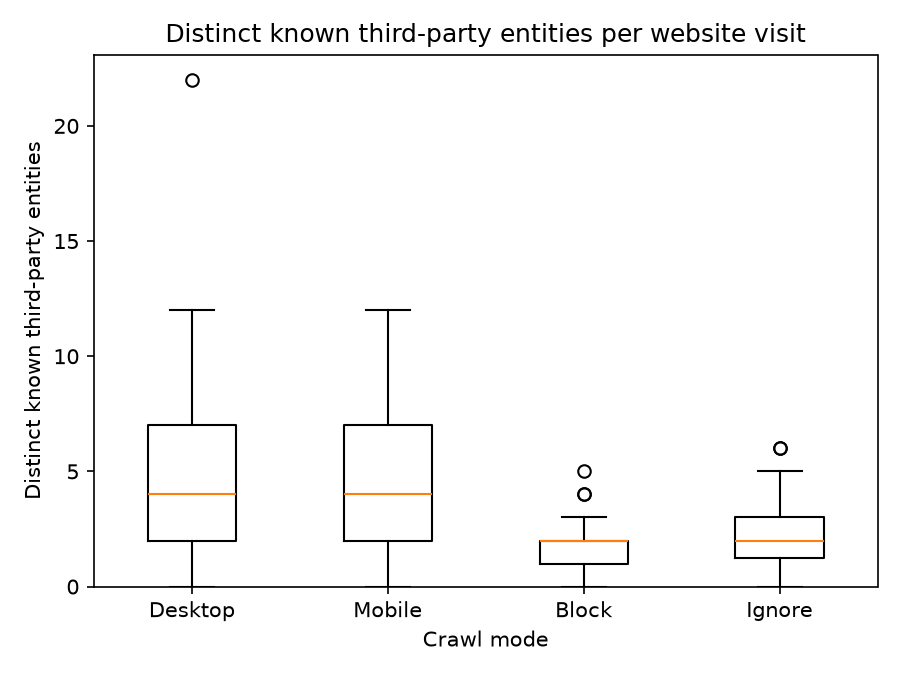

In [7]:
show_figure('q1_requests', 'Q1a', 'All received requests per completed website visit, grouped by crawl mode.')
show_figure('q1_third_party_requests', 'Q1b', 'Received third-party requests per completed website visit, grouped by crawl mode.')
show_figure('q1_third_party_domains', 'Q1c', 'Distinct third-party domains per completed website visit, grouped by crawl mode.')
show_figure('q1_third_party_entities', 'Q1d', 'Distinct mapped third-party entities per completed website visit, grouped by crawl mode.')

### Q2. Summary by mode


In [8]:
show_table('q2', 'Q2', 'Minimum / median / maximum of each per-visit metric, grouped by crawl mode.', kind='summary', detail='Mode')

Mode,Sites,All requests,Third-party requests,Third-party domains,Mapped third-party entities
Desktop,30,25 / 104 / 232,8 / 53.5 / 189,2 / 13 / 35,0 / 4 / 22
Mobile,29,25 / 104 / 282,8 / 57 / 190,2 / 15 / 35,0 / 4 / 12
Block,30,21 / 66 / 161,4 / 21.5 / 107,1 / 5 / 12,0 / 2 / 5
Ignore,30,25 / 59.5 / 142,5 / 21 / 86,1 / 6 / 15,0 / 2 / 6


## Advertising and analytics


### Q3. Category prevalence by mode


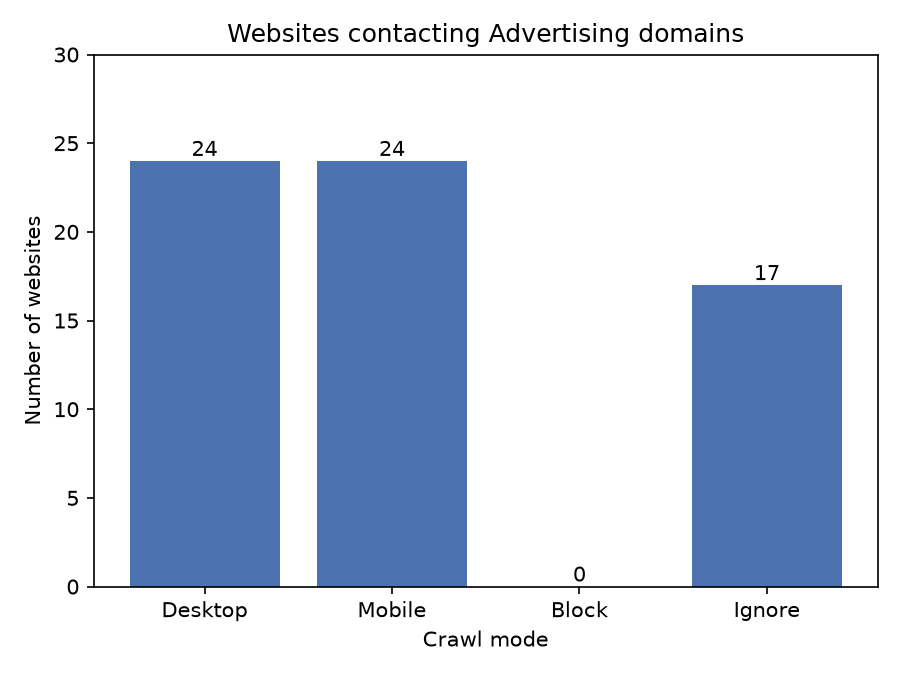

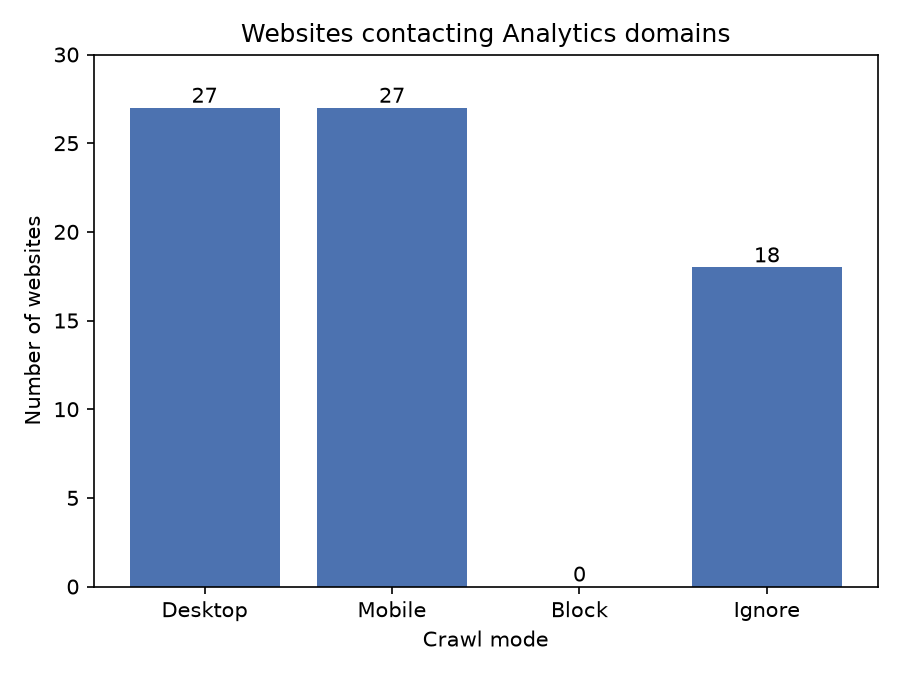

In [9]:
show_figure('q3_advertising', 'Q3a', 'Websites with at least one received Advertising response. Desktop, Mobile, Block and Ignore denominators are 30, 29, 30 and 30.')
show_figure('q3_analytics', 'Q3b', 'Websites with at least one received Analytics response. Desktop, Mobile, Block and Ignore denominators are 30, 29, 30 and 30.')

Category counts include both first- and third-party responses classified by Disconnect. Each website is counted once per category within each group and may count in both categories.


### Q4. Desktop summary by country


In [10]:
show_table('q4', 'Q4', 'Minimum / median / maximum of each per-visit metric for the ten Desktop visits in each country.', kind='summary', detail='Country')

Country,Sites,All requests,Third-party requests,Third-party domains,Mapped third-party entities
NL,10,25 / 91.5 / 146,8 / 38.5 / 83,4 / 10 / 17,0 / 4 / 8
UK,10,82 / 145 / 232,48 / 107.5 / 189,15 / 22.5 / 35,2 / 8.5 / 22
US,10,27 / 75.5 / 141,8 / 22.5 / 87,2 / 8 / 15,0 / 2 / 6


### Q5. Category prevalence without consent interaction


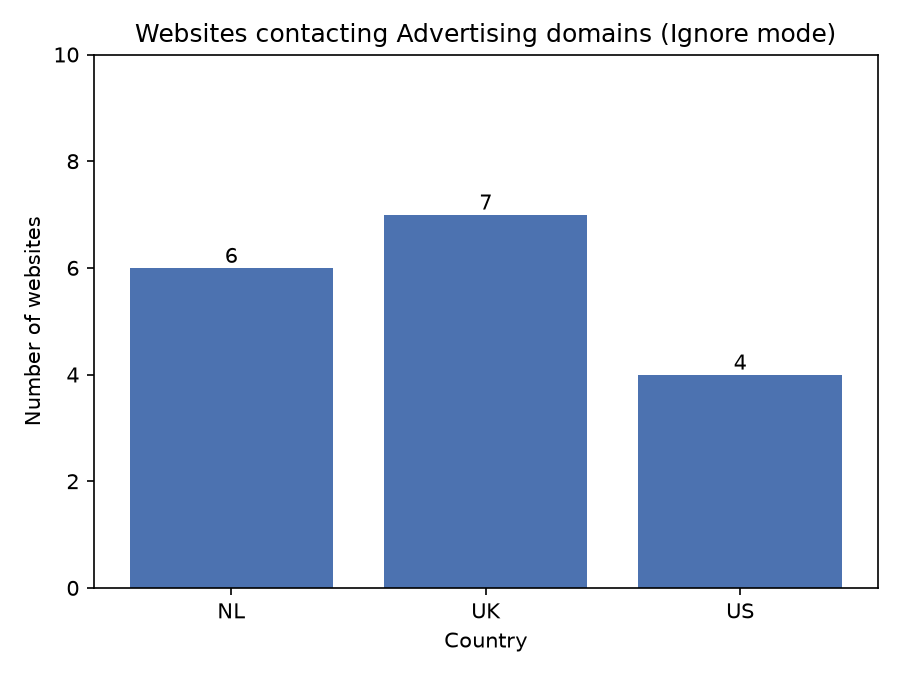

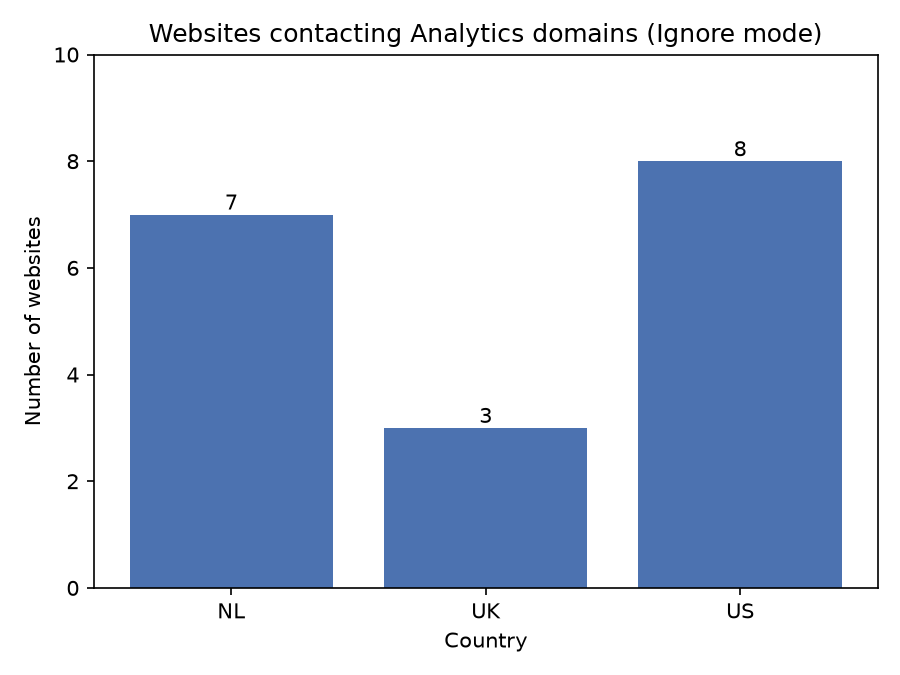

In [11]:
show_figure('q5_advertising', 'Q5a', 'Ignore websites with at least one received Advertising response, out of ten sampled sites per country.')
show_figure('q5_analytics', 'Q5b', 'Ignore websites with at least one received Analytics response, out of ten sampled sites per country.')

## Third-party domain prevalence


### Q6. Domains exclusive to Desktop or Mobile


In [12]:
show_table('q6', 'Q6', 'Three most prevalent third-party domains seen exclusively in each mode across the completed visits. Sites counts distinct websites. Ties are ordered alphabetically by domain. Desktop has 30 visits and Mobile has 29.', kind='table', detail=['Exclusive to', 'Third-party domain', 'Sites'])

Exclusive to,Third-party domain,Sites
Desktop only,3lift.com,1
Desktop only,adobedtm.com,1
Desktop only,adroll.com,1
Mobile only,crazyegg.com,4
Mobile only,mpc-prod-27-s6uit34pua-uk.a.run.app,3
Mobile only,on.aws,3


### Q7. Top domains by mode

The rankings count each website once per third-party domain. Ties are ordered alphabetically by domain. Categories are the union of labels observed for that domain in the mode. NA indicates that no category was assigned in those observations.


In [13]:
show_table('q7_desktop', 'Q7a', 'Desktop mode. Ten most prevalent third-party domains by number of websites, out of 30 completed visits.', kind='table', detail=['Rank', 'Third-party domain', 'Sites', 'Disconnect categories'])

Rank,Third-party domain,Sites,Disconnect categories
1,googletagmanager.com,28,NA
2,google.com,24,Advertising; Analytics; Content; FingerprintingGeneral
3,doubleclick.net,23,Advertising; Email; FingerprintingGeneral
4,google.nl,21,Content
5,facebook.net,16,FingerprintingGeneral; Social
6,google-analytics.com,15,Analytics; Email; FingerprintingGeneral
7,licdn.com,14,Social
8,linkedin.com,14,Social
9,gstatic.com,9,Content
10,siteimproveanalytics.com,9,Analytics


In [14]:
show_table('q7_mobile', 'Q7b', 'Mobile mode. Ten most prevalent third-party domains by number of websites, out of 29 completed visits.', kind='table', detail=['Rank', 'Third-party domain', 'Sites', 'Disconnect categories'])

Rank,Third-party domain,Sites,Disconnect categories
1,googletagmanager.com,27,NA
2,google.com,23,Advertising; Analytics; Content; FingerprintingGeneral
3,doubleclick.net,22,Advertising; Email; FingerprintingGeneral
4,google.nl,20,Content
5,facebook.com,15,FingerprintingGeneral; Social
6,facebook.net,15,FingerprintingGeneral; Social
7,google-analytics.com,15,Analytics; Email; FingerprintingGeneral
8,licdn.com,13,Social
9,linkedin.com,13,Social
10,googlesyndication.com,10,Advertising; FingerprintingGeneral


## Domain rankings


### Q7. Top domains by mode (continued)


In [15]:
show_table('q7_block', 'Q7c', 'Block mode. Ten most prevalent third-party domains by number of websites, out of 30 completed visits. NA indicates no observed category.', kind='table', detail=['Rank', 'Third-party domain', 'Sites', 'Disconnect categories'])

Rank,Third-party domain,Sites,Disconnect categories
1,googletagmanager.com,28,NA
2,google.nl,19,Content
3,gstatic.com,9,Content
4,fonts.googleapis.com,8,Content
5,youtube.com,7,Content
6,cloudflare.com,6,Content
7,jsdelivr.net,4,Content
8,onetrust.com,4,ConsentManagers
9,typekit.net,4,NA
10,ytimg.com,4,Content


In [16]:
show_table('q7_ignore', 'Q7d', 'Ignore mode. Ten most prevalent third-party domains by number of websites, out of 30 completed visits. NA indicates no observed category.', kind='table', detail=['Rank', 'Third-party domain', 'Sites', 'Disconnect categories'])

Rank,Third-party domain,Sites,Disconnect categories
1,googletagmanager.com,23,NA
2,google-analytics.com,10,Analytics; Email; FingerprintingGeneral
3,googlesyndication.com,9,Advertising; FingerprintingGeneral
4,google.com,8,Advertising; Analytics; Content
5,gstatic.com,8,Content
6,fonts.googleapis.com,7,Content
7,cloudflare.com,6,Content
8,doubleclick.net,6,Advertising; Email; FingerprintingGeneral
9,youtube.com,6,Content
10,google.nl,5,Content


### Q8. Desktop extremes and popularity


In [17]:
show_table('q8_highest_desktop', 'Q8a', 'Three Desktop websites with the most distinct third-party domains. Tranco ranks are dated 14 November 2026. Ties are ordered alphabetically.', kind='rank', detail=None)

Website,Tranco rank,Country,Third-party domains
nottingham.ac.uk,8694,UK,35
leeds.ac.uk,5980,UK,31
manchester.ac.uk,4956,UK,31


In [18]:
show_table('q8_lowest_desktop', 'Q8b', 'Three Desktop websites with the fewest distinct third-party domains. Tranco ranks are dated 14 November 2026. Ties are ordered alphabetically.', kind='rank', detail=None)

Website,Tranco rank,Country,Third-party domains
mit.edu,233,US,2
utwente.nl,6575,NL,4
upenn.edu,1269,US,5


## Session replay and response policies


### Q9. Requests to session replay domains


In [19]:
show_table('q9', 'Q9', 'Website–domain pairs with a received response from a domain flagged for session replay by Disconnect. Modes list where each pair was observed. The flag identifies the domain and cannot establish whether replay code ran.', kind='table', detail=['Website', 'Country', 'Session replay domain', 'Observed modes'])

Website,Country,Session replay domain,Observed modes
lse.ac.uk,UK,hotjar.com,"Desktop, Mobile"
lse.ac.uk,UK,hotjar.io,"Desktop, Mobile"
manchester.ac.uk,UK,hotjar.com,"Desktop, Mobile"
warwick.ac.uk,UK,hotjar.com,"Desktop, Mobile"
stanford.edu,US,contentsquare.net,"Desktop, Mobile, Ignore"
uchicago.edu,US,hotjar.com,"Desktop, Mobile, Ignore"
uchicago.edu,US,hotjar.io,Ignore


### Q10. Explicitly disabled permissions


In [20]:
show_table('q10', 'Q10', 'Five most frequently disabled permissions among Mobile first-party responses. Each site is counted once per permission with an explicit empty allowlist. Seven of 29 completed Mobile visits received a first-party Permissions-Policy header.', kind='table', detail=['Permission', 'Sites disabling', 'Sites sending header'])

Permission,Sites disabling,Sites sending header
microphone,5,7
camera,4,7
gyroscope,3,7
magnetometer,3,7
payment,2,7


### Q11. Effective no-referrer policy


In [21]:
show_table('q11', 'Q11', 'Desktop websites with at least one first-party response whose effective Referrer-Policy was no-referrer. The response count uses the last recognized token across repeated headers and comma-separated fallback values.', kind='table', detail=['Website', 'Country', 'Qualifying responses'])

Website,Country,Qualifying responses
uva.nl,NL,55


Q10 and Q11 measure headers on individual first-party responses, including subresources and redirects. Their counts describe the presence of these headers in the captured traffic.


## CNAME matches


### Q12. First-party aliases to listed domains

The analysis followed cached CNAME chains for 48 distinct observed first-party request subdomains. Lookups were made on 17 November 2026, 00:20:53–00:21:00 UTC. Thirty lookups returned a chain and 18 returned no CNAME. The cache recorded no lookup failures. Each distinct matching target, entity and category combination is listed by crawl mode.


In [22]:
show_table('q12_desktop', 'Q12a', 'Desktop mode. First-party request subdomains whose cached CNAME chains contained a target matched to a Disconnect service.', kind='table', detail=['First-party subdomain', 'CNAME target', 'Entity', 'Category'])

First-party subdomain,CNAME target,Entity,Category
www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
smetrics.nottingham.ac.uk,oacflwpnfh.data.adobedc.net,Adobe,Analytics
www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrerhnepdbhbag.a01.azurefd.net,Microsoft,Content
www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content
cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content


In [23]:
show_table('q12_mobile', 'Q12b', 'Mobile mode. First-party request subdomains whose cached CNAME chains contained a target matched to a Disconnect service.', kind='table', detail=['First-party subdomain', 'CNAME target', 'Entity', 'Category'])

First-party subdomain,CNAME target,Entity,Category
www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrerhnepdbhbag.a01.azurefd.net,Microsoft,Content
www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content
cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content


In [24]:
show_table('q12_block', 'Q12c', 'Block mode. First-party request subdomains whose cached CNAME chains contained a target matched to a Disconnect service.', kind='table', detail=['First-party subdomain', 'CNAME target', 'Entity', 'Category'])

First-party subdomain,CNAME target,Entity,Category
www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
smetrics.nottingham.ac.uk,oacflwpnfh.data.adobedc.net,Adobe,Analytics
www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrerhnepdbhbag.a01.azurefd.net,Microsoft,Content
www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content
cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content


In [25]:
show_table('q12_ignore', 'Q12d', 'Ignore mode. First-party request subdomains whose cached CNAME chains contained a target matched to a Disconnect service.', kind='table', detail=['First-party subdomain', 'CNAME target', 'Entity', 'Category'])

First-party subdomain,CNAME target,Entity,Category
www.manchester.ac.uk,duc7h5khrpi4j.cloudfront.net,Amazon,Content
www.uchicago.edu,hubba882888a582-prod-frontdoor-endpoint-gkbrerhnepdbhbag.a01.azurefd.net,Microsoft,Content
www.ucla.edu,d1zev4mn1zpfbc.cloudfront.net,Amazon,Content
cdn.webcomponents.ucla.edu,d3nstw201xsr54.cloudfront.net,Amazon,Content


## Discussion and reproducibility


### Q13a. Most interesting observed difference

Leaving consent untouched still exposed a substantial part of the university sample to requests in two measured categories. In Ignore, 17 of 30 sites contacted Advertising domains and 18 of 30 contacted Analytics domains, compared with 24 and 27 in Desktop. Block returned zero in both categories (Q3), yet the median Block visit still received 21.5 third-party responses (Q2). The categories covered by the blocking rules therefore explain only part of the third-party traffic observed across the four modes. The Adobe Analytics match behind smetrics.nottingham.ac.uk in Block (Q12) also shows why inspecting DNS can reveal connections hidden by a comparison of registrable domains alone. A listed alias establishes a DNS association, with the purpose of the individual request left unresolved.


### Q13b. A limitation and its effect

The mode comparisons use one completed visit per site and mode, with Ignore run earlier than the other configurations and with a shorter observation sequence. Timing and the shorter window could affect which requests are captured, so the observed differences cannot be attributed solely to consent interaction. The failed Nottingham Mobile visit also matters for Q6 because Nottingham led Desktop with 35 distinct third-party domains. A repeat using the same 30 sites in every mode could change which domains appear exclusive to Desktop or Mobile.


### Q13c. Technical challenge and response

One challenge documented in the collection records was distinguishing a completed visit from one with incomplete consent handling. The crawler retained diagnostic artifacts for the failed Nottingham Mobile visit and the preparation step excluded it from the completed dataset. This avoided treating the failure as a zero-traffic observation, while leaving the Mobile coverage gap explicit.


### Data and reference snapshots

The report uses the prepared visits.csv and requests.csv, the Q1–Q12 outputs, and the archived Q12 DNS cache. Regenerating the analysis from those inputs and local references reproduced every result CSV and chart. Response counts were also reconciled to visits.csv by website and mode.

Reference sources were the instructor-supplied university list, Disconnect services revision a277cd6, Disconnect entity map revision cb1b0c1, and the local Public Suffix List snapshot retrieved 3 November 2026. Q8 uses the local Tranco extract dated 14 November 2026. The extract does not record a list ID or retrieval date. Q12 DNS was queried after the crawl, so the saved answers may differ from the records present during collection.
